<a href="https://colab.research.google.com/github/LBorges13/IPA_BD/blob/main/PI06_Genial_Prospect_(Churn).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Genial Prospect - Modelo de ML para Análise de Churn.**
---
Este pipeline tem como objetivo criamos o Modelo de Machine Learning para a análise preditiva de possiveis Churn.

## 1 Preparativos e Requisitos
---

Entendendo os requisitos do projeto para realizar o modelo de machine learning

---

Para o projeto de implementação que estamos utilizando para a predição, utilizaremos a base da Genial Investimento para análise de Métricas e Valores estipulantes.

Agora, vamos formular a Amostra ideal para a análise preditiva.

### 1.1 Análise Estátistica Descritiva
---


Tamanho da Amostra se dá com a formula:


**n=(Z^2.p.(1-p))/e^2**

Sendo estes:

*   n= Quantidade Ideal da Amostra
*   Z= Nível de Confiança
*   p= Proporção de Classe Esperada (Percentual do Churn -esperado-)
*   e= Margem de Erro

E, com base nisso, pegamos as informações no banco de dados e sendo bem criteriosos com base no nível de confiança e margem de erro (sendo considerados os valores 99% e 3%, respectivamente).

Temos o valor da amostra de **1.690** unidades de registro.

### 1.2 Bibliotecas

In [1]:
#Instalação da Biblioteca utilizada
!pip install psycopg2

In [2]:
#Importação das Bibliotecas Utilizadas
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import psycopg2

### 1.3 Conexão com o Banco de Dados

In [3]:
#Conexão com o Data Warehoouse

dict_config = {
  "host": "instanciagenialprospects.ct2ggs6agh8r.us-east-2.rds.amazonaws.com",
  "database": "postgres",
  "user": "postgres",
  "password": "ProjetoIntegrador6",
  "port": "5432"
  }

conn = psycopg2.connect(**dict_config)

In [4]:
#Pegando cada tabela
query = '''
SELECT c.id_cliente, c.dt_nasc, c.tp_pessoa, c.trader_declarado,
       c.perfil_suitability, c.sexo, c.estado_civil, c.cidade, c.uf,
       c.profissao, c.valor_rendimentos, c.valor_patrimonio, s.status,
       s.data_habilitacao, s.data_ativacao, s.ultima_data_negociacao
FROM ds.cliente c
JOIN ds.status_cliente s ON
c.id_cliente = s.id_cliente
WHERE s.status IN ('CHURN', 'ATIVO')
ORDER BY RANDOM()
LIMIT 1690;
'''

with conn.cursor() as cursor:
        cursor.execute(query)
        data = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]


df = pd.DataFrame(data, columns=columns)

## **2 Análise Exploratória de Dados (EDA - Exploratory Data Analysis)**

### 2.1 Descrição da Tabela

In [5]:
df.head()

,id_cliente,dt_nasc,tp_pessoa,trader_declarado,perfil_suitability,sexo,estado_civil,cidade,uf,profissao,valor_rendimentos,valor_patrimonio,status,data_habilitacao,data_ativacao,ultima_data_negociacao
0,4415892,2003-06-10,F,NÃO TRADER,Conservador,F,SOLTEIRO(A),RIO DE JANEIRO,RJ,TRABALHADOR AUTONOMO,1000.00,100.00,ATIVO,2024-04-11,2024-04-11,None
1,5332034,2006-09-16,F,NÃO TRADER,Arrojado,M,SOLTEIRO(A),SAO PAULO,SP,ELETRICISTA E ASSEMELHADOS,1800.00,671.00,CHURN,2024-12-23,2024-12-27,2025-01-31
2,878002,1959-07-27,F,NÃO DECLARADO,Arrojado,F,CASADO(A),PARANAVAI,PR,ADMINISTRADOR,5000.00,None,CHURN,2017-03-21,2018-01-21,None
3,2118420,1995-10-16,F,NÃO TRADER,Conservador,F,SOLTEIRO(A),SANTA LUZIA,MA,ODONTÓLOGO,3500.00,0.00,ATIVO,2022-02-13,2022-02-14,None
4,8354,1980-04-21,F,NÃO DECLARADO,Arrojado,M,SOLTEIRO(A),SAO PAULO,SP,ENGENHEIRO,11000.00,785000.00,CHURN,2018-10-04,2018-01-21,None


In [6]:
df.columns

Index(['id_cliente', 'dt_nasc', 'tp_pessoa', 'trader_declarado',
       'perfil_suitability', 'sexo', 'estado_civil', 'cidade', 'uf',
       'profissao', 'valor_rendimentos', 'valor_patrimonio', 'status',
       'data_habilitacao', 'data_ativacao', 'ultima_data_negociacao'],
      dtype='object')

### 2.2 Validando Colunas

In [7]:
#Validando valores únicos para a chave primária
df['id_cliente'].is_unique

True

In [8]:
#Quantidade de Churn e Ativos
df['status'].value_counts()

,count
status,
CHURN,1092
ATIVO,598


In [9]:
list_columns_cat = ['tp_pessoa', 'sexo', 'estado_civil', 'profissao', 'perfil_suitability']
list_columns_num = ['valor_rendimentos', 'valor_patrimonio']
list_columns_date = ['dt_nasc', 'data_habilitacao', 'data_ativacao', 'ultima_data_negociacao']

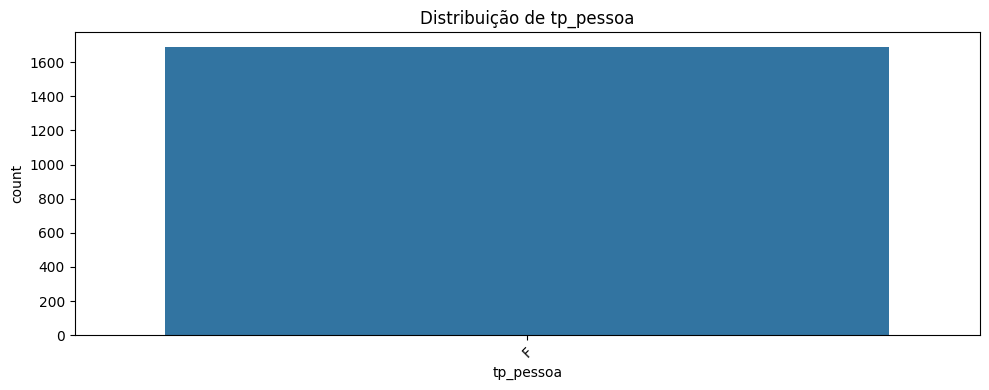

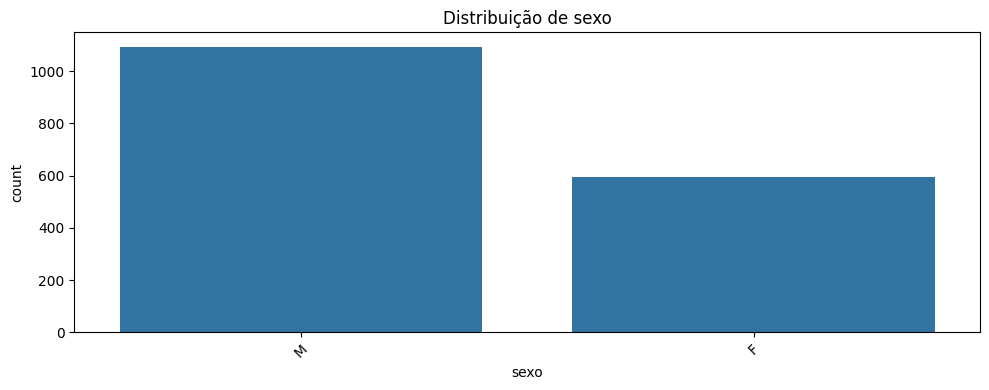

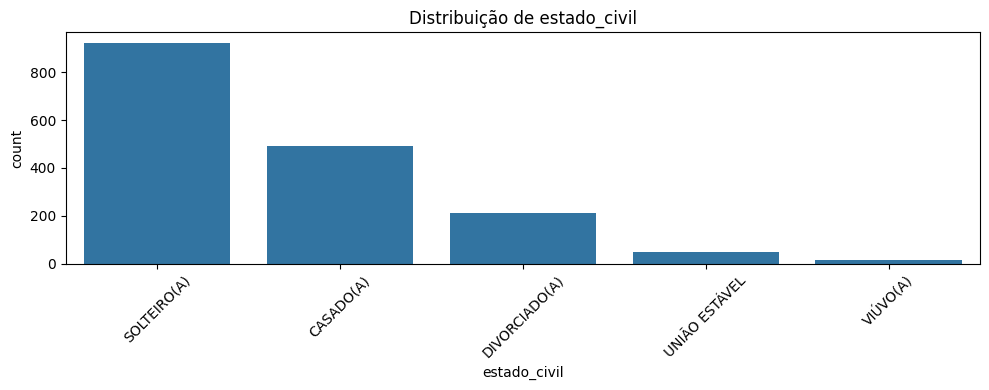

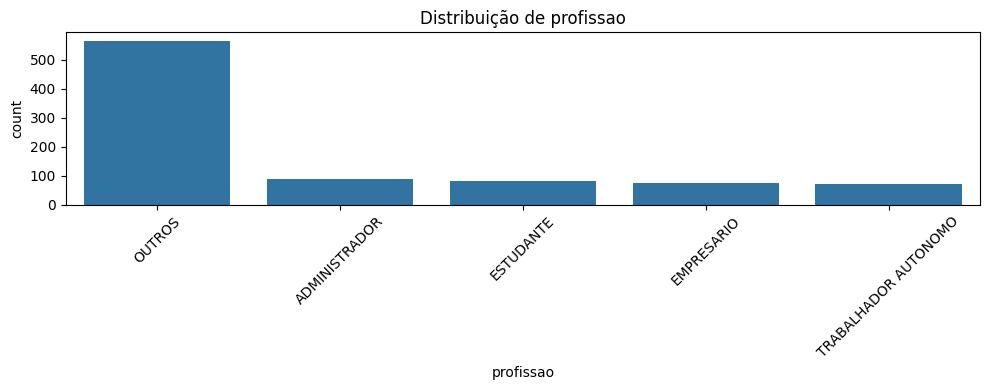

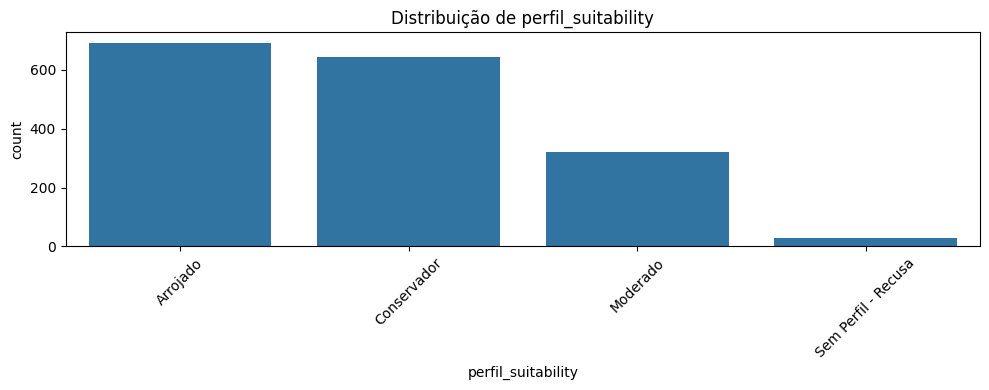

In [10]:
import matplotlib.pyplot as plt

for col in list_columns_cat:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts()[:5].index)
    plt.title(f'Distribuição de {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [11]:
for col in list_columns_num:
    df[col] = df[col].fillna('0')
    df[col] = df[col].astype(float)

df[list_columns_num].head()

,valor_rendimentos,valor_patrimonio
0,1000.0,100.0
1,1800.0,671.0
2,5000.0,0.0
3,3500.0,0.0
4,11000.0,785000.0


In [12]:
#Validando Tipos
df.dtypes

,0
id_cliente,int64
dt_nasc,object
tp_pessoa,object
trader_declarado,object
perfil_suitability,object
sexo,object
estado_civil,object
cidade,object
uf,object
profissao,object


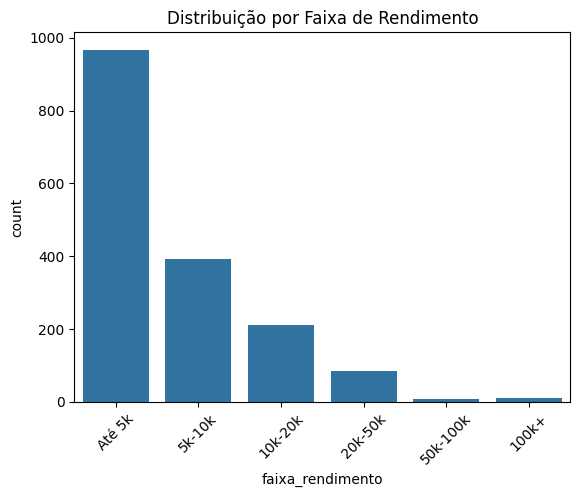

In [13]:
# Exemplo com valor_rendimentos
df['faixa_rendimento'] = pd.cut(df['valor_rendimentos'],
                                bins=[0, 5000, 10000, 20000, 50000, 100000, df['valor_rendimentos'].max()],
                                labels=['Até 5k', '5k-10k', '10k-20k', '20k-50k', '50k-100k', '100k+'])

sns.countplot(data=df, x='faixa_rendimento')
plt.title('Distribuição por Faixa de Rendimento')
plt.xticks(rotation=45)
plt.show()

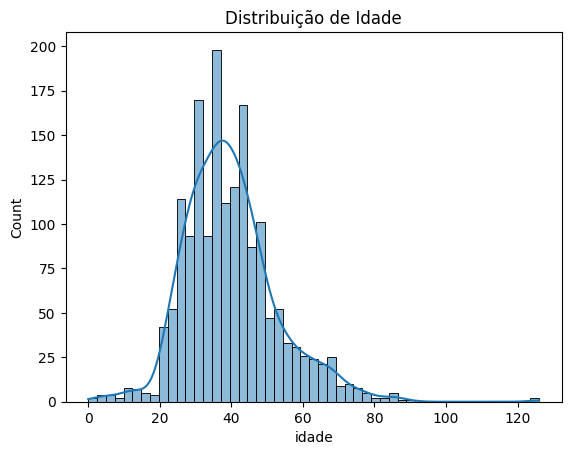

In [14]:
from datetime import datetime

# Supondo que dt_nasc está no formato datetime
df['idade'] = (pd.to_datetime('today') - pd.to_datetime(df['dt_nasc'])).dt.days // 365
df['dias_desde_ativacao'] = (pd.to_datetime('today') - pd.to_datetime(df['data_ativacao'])).dt.days
df['dias_desde_ultima_negociacao'] = (pd.to_datetime('today') - pd.to_datetime(df['ultima_data_negociacao'])).dt.days

# Visualizar distribuição de idade
sns.histplot(df['idade'], kde=True)
plt.title('Distribuição de Idade')
plt.show()

In [15]:
from scipy.stats import skew, kurtosis

print("Assimetria (Skew):", skew(df['idade']))
print("Curtose:", kurtosis(df['idade']))

Assimetria (Skew): 0.9286487357171564
Curtose: 2.880500495917265


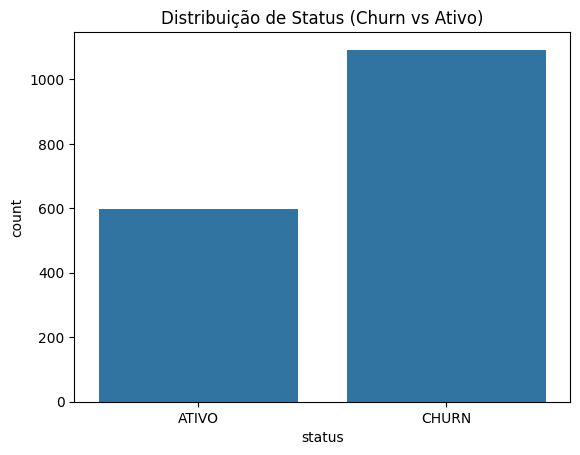

status
CHURN    0.646154
ATIVO    0.353846
Name: proportion, dtype: float64


In [16]:
sns.countplot(data=df, x='status')
plt.title('Distribuição de Status (Churn vs Ativo)')
plt.show()

print(df['status'].value_counts(normalize=True))

### 2.3 Análise Bivariada

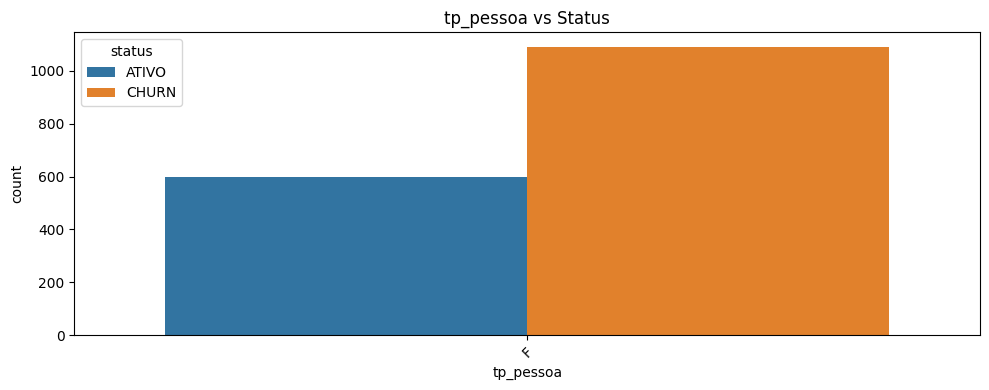

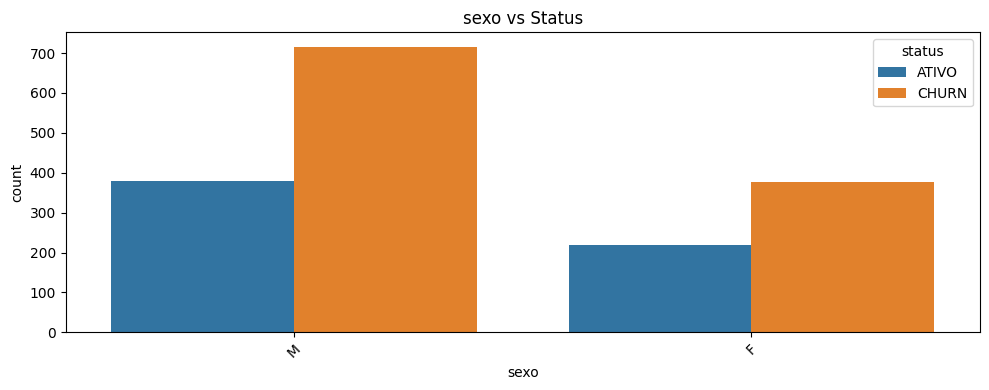

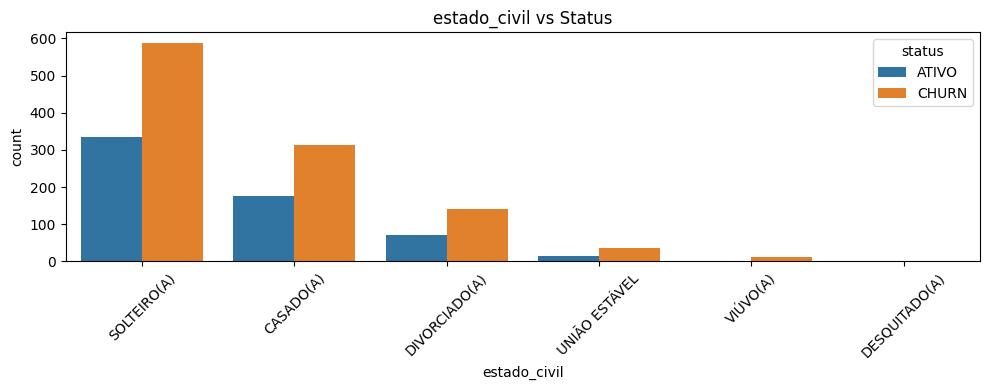

/tmp/ipython-input-1026343569.py:6: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


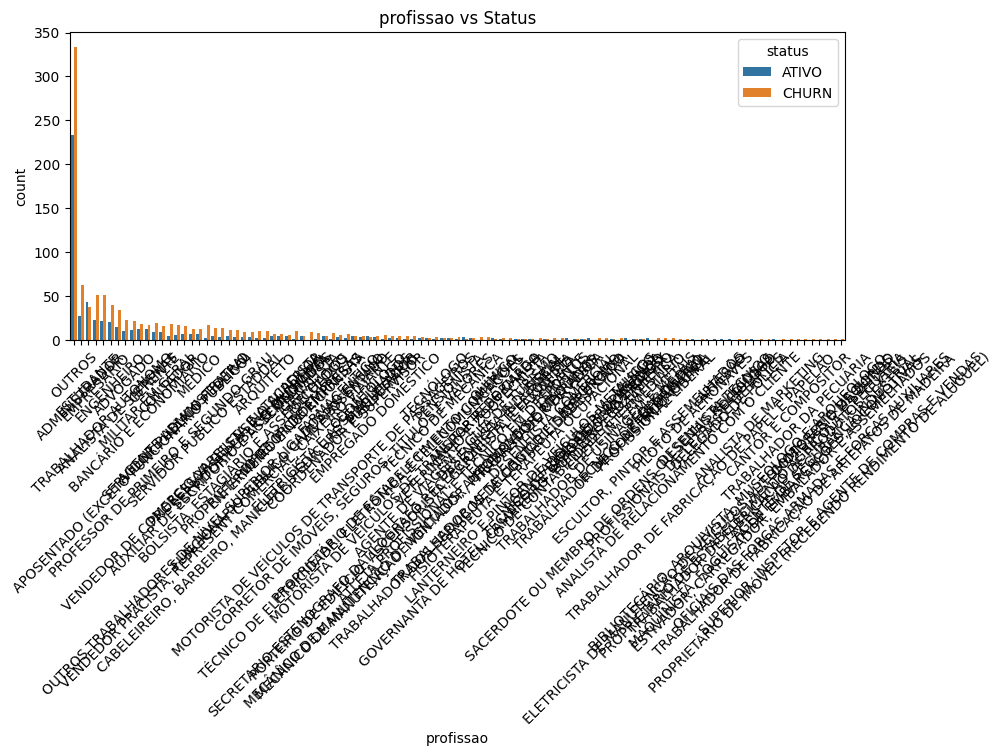

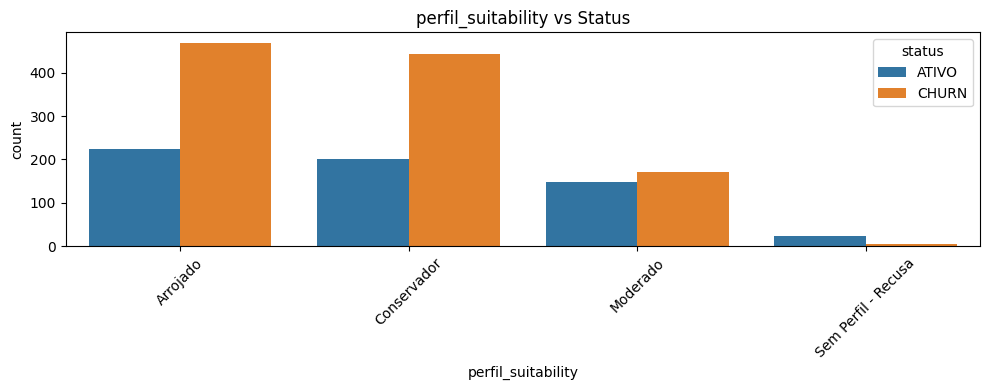

In [17]:
for col in list_columns_cat:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, hue='status', order=df[col].value_counts().index)
    plt.title(f'{col} vs Status')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [18]:
for col in list_columns_cat:
    prop = df.groupby(col)['status'].value_counts(normalize=True).unstack()
    display(prop.style.background_gradient(cmap='Blues'))

status,ATIVO,CHURN
tp_pessoa,,
F,0.353846,0.646154


status,ATIVO,CHURN
sexo,,
F,0.369128,0.630872
M,0.345521,0.654479


status,ATIVO,CHURN
estado_civil,,
CASADO(A),0.359184,0.640816
DESQUITADO(A),nan,1.000000
DIVORCIADO(A),0.338028,0.661972
SOLTEIRO(A),0.362649,0.637351
UNIÃO ESTÁVEL,0.280000,0.720000
VIÚVO(A),0.133333,0.866667


status,ATIVO,CHURN
profissao,,
ADMINISTRADOR,0.300000,0.700000
ADVOGADO,0.303030,0.696970
AGENCIADOR DE PROPAGANDA,0.500000,0.500000
AGENTE ADMINISTRATIVO,0.304348,0.695652
AGENTE DE SEGURANÇA INDUSTRIAL,nan,1.000000
AGENTE DE VIAGEM E GUIA DE TURISMO,0.250000,0.750000
AGRÔNOMO,1.000000,nan
ANALISTA DE MARKETING,nan,1.000000
ANALISTA DE RELACIONAMENTO COM O CLIENTE,nan,1.000000


status,ATIVO,CHURN
perfil_suitability,,
Arrojado,0.323232,0.676768
Conservador,0.313665,0.686335
Moderado,0.462500,0.537500
Sem Perfil - Recusa,0.827586,0.172414


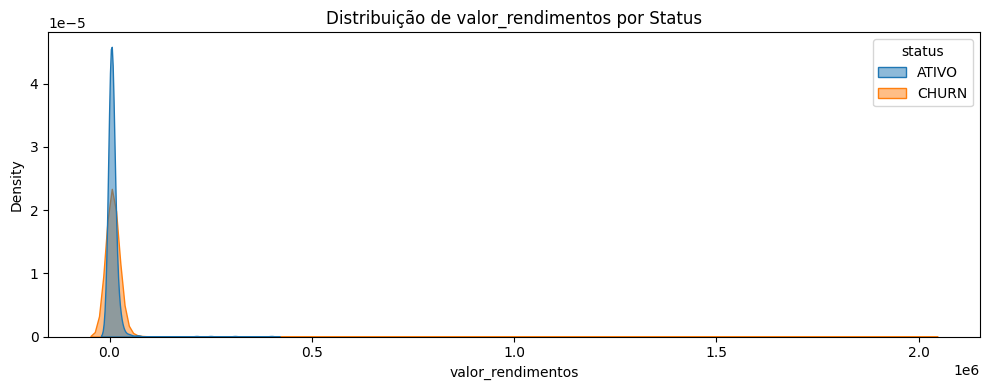

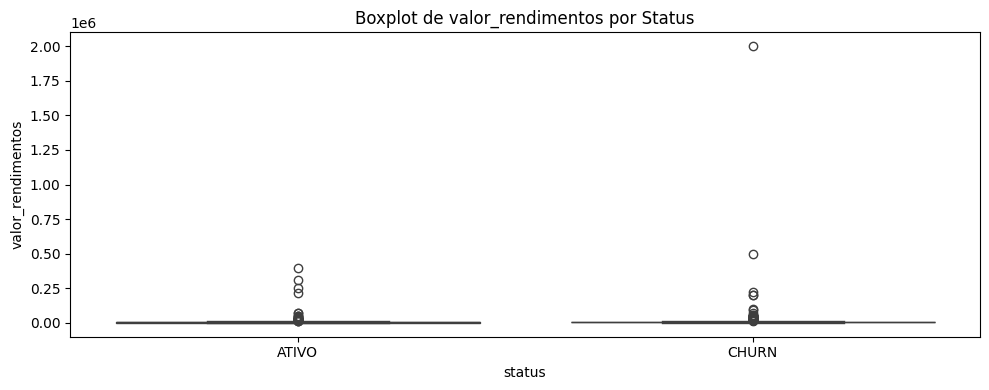

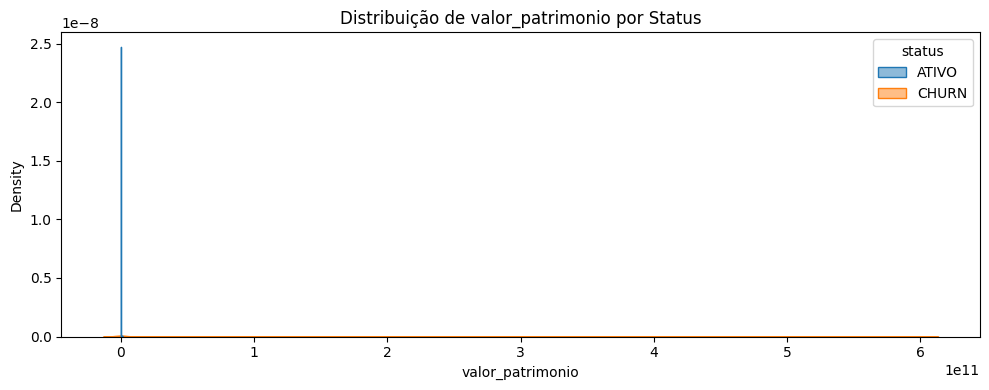

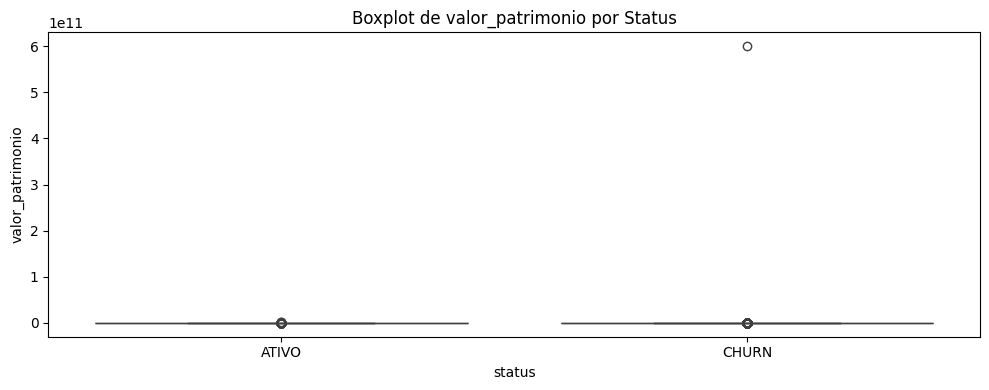

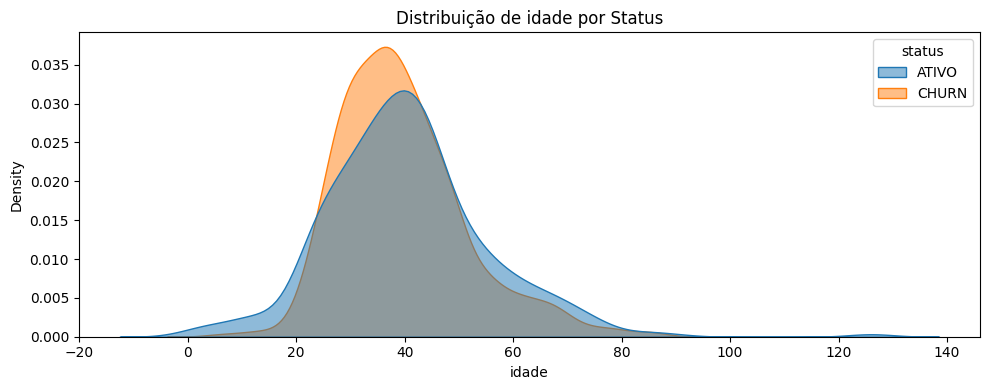

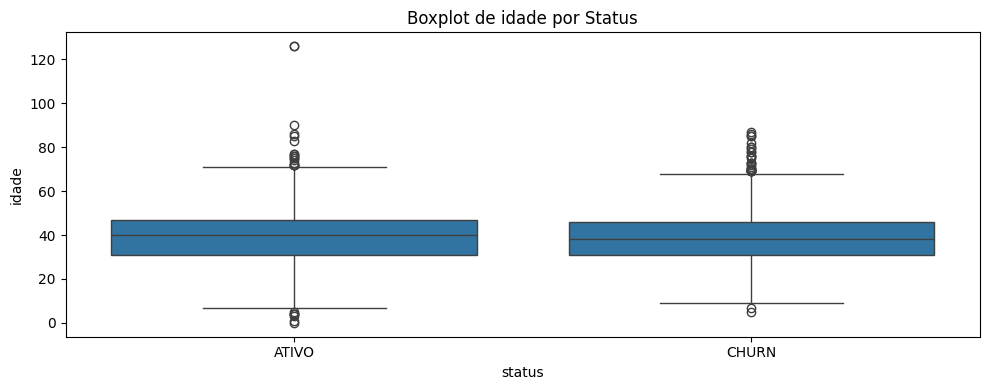

In [19]:
num_cols = ['valor_rendimentos', 'valor_patrimonio', 'idade']

for col in num_cols:
    plt.figure(figsize=(10, 4))
    sns.kdeplot(data=df, x=col, hue='status', fill=True, common_norm=False, alpha=0.5)
    plt.title(f'Distribuição de {col} por Status')
    plt.tight_layout()
    plt.show()

    # Boxplot
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df, x='status', y=col)
    plt.title(f'Boxplot de {col} por Status')
    plt.tight_layout()
    plt.show()

In [20]:
from scipy.stats import mannwhitneyu

ativo = df[df['status'] == 'ATIVO']['idade']
churn = df[df['status'] == 'CHURN']['idade']

stat, p = mannwhitneyu(ativo, churn)
print(f'p-valor: {p}')

if p < 0.05:
    print("Diferença significativa entre idades de ATIVO e CHURN")
else:
    print("Diferença não significativa")

p-valor: 0.134805346266775
Diferença não significativa


In [21]:
from scipy.stats import ttest_ind

stat, p = ttest_ind(ativo, churn)
print(f'p-valor: {p}')

p-valor: 0.16522860909708872


In [22]:
df_num = df[num_cols].copy()

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_num), columns=num_cols)

In [24]:
corr_matrix = df_scaled.corr()

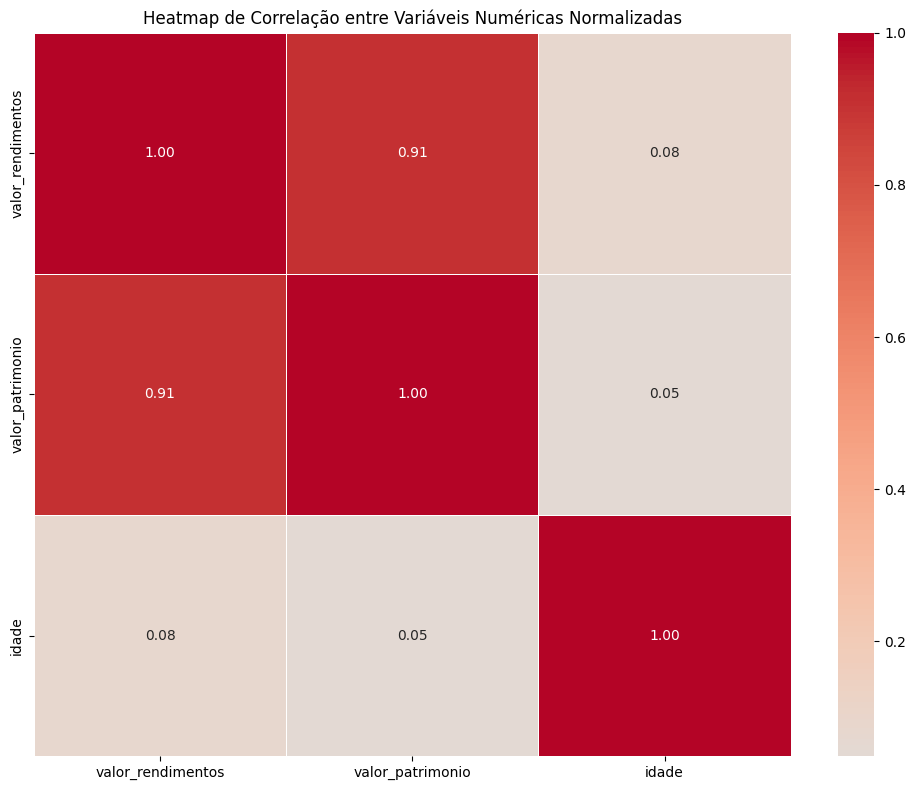

In [25]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f", linewidths=0.5)
plt.title('Heatmap de Correlação entre Variáveis Numéricas Normalizadas')
plt.tight_layout()
plt.show()


In [26]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
cat_cols = ['tp_pessoa', 'trader_declarado', 'perfil_suitability', 'sexo', 'estado_civil', 'cidade', 'uf', 'profissao']

le = LabelEncoder()
for col in cat_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

In [27]:
# corr_matrix = df_encoded[cat_cols + ['status_bin']].corr()

# plt.figure(figsize=(12, 8))
# sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f", linewidths=0.5)
# plt.title('Correlação entre Variáveis Categóricas Codificadas')
# plt.tight_layout()
# plt.show()

## **3 Tratamento de Dados**

### 3.1 Transformando Features (Variáveis)

In [28]:
from datetime import datetime

# Convertendo datas para datetime
df['dt_nasc'] = pd.to_datetime(df['dt_nasc'])
df['data_ativacao'] = pd.to_datetime(df['data_ativacao'])
df['ultima_data_negociacao'] = pd.to_datetime(df['ultima_data_negociacao'])

# Criando variáveis derivadas
df['idade'] = (pd.to_datetime('today') - df['dt_nasc']).dt.days // 365
df['dias_desde_ativacao'] = (pd.to_datetime('today') - df['data_ativacao']).dt.days
df['dias_desde_ultima_negociacao'] = (pd.to_datetime('today') - df['ultima_data_negociacao']).dt.days


### 3.2 Redigindo Nulos

In [29]:
# Verificar nulos
print(df.isnull().sum())

# Imputar valores numéricos com média
num_cols = ['valor_rendimentos', 'valor_patrimonio', 'idade', 'dias_desde_ativacao', 'dias_desde_ultima_negociacao']
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Imputar categóricas com moda
cat_cols = ['tp_pessoa', 'trader_declarado', 'perfil_suitability', 'sexo', 'estado_civil', 'cidade', 'uf', 'profissao']
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])


id_cliente                         0
dt_nasc                            0
tp_pessoa                          0
trader_declarado                   0
perfil_suitability                 4
sexo                               0
estado_civil                       0
cidade                            69
uf                                49
profissao                          0
valor_rendimentos                  0
valor_patrimonio                   0
status                             0
data_habilitacao                   0
data_ativacao                     10
ultima_data_negociacao          1348
faixa_rendimento                  19
idade                              0
dias_desde_ativacao               10
dias_desde_ultima_negociacao    1348
dtype: int64


### 3.1 Normalizando Colunas

In [30]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

In [32]:
df['status_bin'] = df['status'].map({'CHURN': 1, 'ATIVO': 0})

## **4 Criação do Modelo**

### 4.1 Pré-Prativa do Dataframe

In [33]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separar features e target
X = df.drop(columns=['status_bin'])  # substitua 'status_bin' pelo nome da sua variável alvo
y = df['status_bin']

# Tratar colunas de data (como antes)
for col in X.select_dtypes(include=['object', 'datetime']).columns:
    try:
        X[col] = pd.to_datetime(X[col])
        X[f'{col}_ano'] = X[col].dt.year
        X[f'{col}_mes'] = X[col].dt.month
        X[f'{col}_dia'] = X[col].dt.day
        X[f'{col}_semana'] = X[col].dt.weekday
        X.drop(columns=[col], inplace=True)
    except:
        pass

# Manter apenas colunas numéricas
X = X.select_dtypes(include=['number'])

# Tratar NaNs
X = X.fillna(X.mean())

# Dividir antes do SMOTE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Aplicar SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Normalizar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

/tmp/ipython-input-3717375871.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  X[col] = pd.to_datetime(X[col])


### 4.2 Treinando Modelos de Classificação (SVM, Regressão Logistica e Floresta Aleatória)

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# 1. Regressão Logística
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train_resampled)
y_pred_lr = lr_model.predict(X_test_scaled)
print("Logistic Regression:\n", classification_report(y_test, y_pred_lr))

# 2. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf_model.predict(X_test)
print("Random Forest:\n", classification_report(y_test, y_pred_rf))

# 3. SVM
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train_resampled)
y_pred_svm = svm_model.predict(X_test_scaled)
print("SVM:\n", classification_report(y_test, y_pred_svm))


Logistic Regression:
               precision    recall  f1-score   support

           0       0.42      0.50      0.46       121
           1       0.69      0.62      0.65       217

    accuracy                           0.58       338
   macro avg       0.56      0.56      0.56       338
weighted avg       0.59      0.58      0.58       338

Random Forest:
               precision    recall  f1-score   support

           0       0.62      0.53      0.57       121
           1       0.76      0.82      0.79       217

    accuracy                           0.72       338
   macro avg       0.69      0.67      0.68       338
weighted avg       0.71      0.72      0.71       338

SVM:
               precision    recall  f1-score   support

           0       0.52      0.41      0.46       121
           1       0.71      0.79      0.75       217

    accuracy                           0.65       338
   macro avg       0.61      0.60      0.60       338
weighted avg       0.64      0

### 4.3 Análise de Resultados sobre cada Modelo

### 4.4 Ajustando Hiperparametros

In [36]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='f1_macro')
grid_search.fit(X_train_resampled, y_train_resampled)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
print("Melhor Random Forest:\n", classification_report(y_test, y_pred_best))


Melhor Random Forest:
               precision    recall  f1-score   support

           0       0.56      0.19      0.28       121
           1       0.67      0.92      0.77       217

    accuracy                           0.66       338
   macro avg       0.62      0.55      0.53       338
weighted avg       0.63      0.66      0.60       338



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


### 4.5 Salvando o Modelo

In [ ]:
import pickle

# Salvar o modelo em um arquivo
with open('modelo_rf.pkl', 'wb') as arquivo:
    pickle.dump(best_model, arquivo)

In [ ]:
print (X_test)

In [ ]:
print(y_pred_best)

In [ ]:
print(y_test.to_list())

## **5 Conclusão**

Após análise descritiva, percebemos que estamos lindando com uma base de dados que representa, de uma forma desbalançeada, uma distribuição de Churn e Ativos.

Isso explica a disparidade sobre a melhoria das métricas estatística como a precisão, recall e f1-score sobre o modelo Random Forest, este realiza uma técnica conhecida como bagging, que lida bem com dados desbalançeados.

Após inserção de alguns hiperparâmetros, é apresentado um modelo de predição de Churn para a Genial Investimentos que pode prever quase 80% dos seus possíveis clientes evasivos, podendo assim formular estratégias de negócio específicas para estes clientes.